
# Capstone 2 — End-to-End Multi-Agent RAG Pipeline

This notebook builds and evaluates:
- Document ingestion and cleaning
- Chunking with overlap
- Local sentence-transformer embeddings
- FAISS semantic retrieval
- BM25 keyword retrieval
- Hybrid retrieval
- Baseline RAG
- Agentic RAG with LangGraph
- Agents as tools
- Memory
- Retrieval validation and retry loop
- Feedback collection
- BLEU, ROUGE and retrieval relevance evaluation
- Baseline RAG vs Agentic RAG comparison
- LangGraph visualization

**LLM:** Qwen2.5-1.5B-Instruct running locally in Colab.

## 1. Install dependencies

In [5]:
!pip install -q \
    langchain \
    langchain-community \
    langchain-huggingface \
    langchain-text-splitters \
    langgraph \
    faiss-cpu \
    sentence-transformers \
    rank-bm25 \
    rouge-score \
    nltk \
    pandas \
    numpy \
    scikit-learn \
    matplotlib \
    fastapi \
    uvicorn \
    transformers \
    accelerate \
    bitsandbytes


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 12.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 52.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


## 2. Imports

In [6]:
import os
import json
import re
import numpy as np
import pandas as pd

from pathlib import Path
from typing import TypedDict, List, Dict, Any, Optional

from langchain_core.documents import Document
from langchain_core.tools import tool
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter

from langgraph.graph import StateGraph, START, END

from sklearn.metrics.pairwise import cosine_similarity
from rouge_score import rouge_scorer

from rank_bm25 import BM25Okapi

from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline

import torch
import nltk

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

print("Imports successful")


/tmp/ipykernel_3609/2409081169.py:13: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Imports successful


## 3. Check GPU

In [7]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU available. A local LLM will be much slower.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 4. Create the customer-support knowledge base

In [8]:
DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(exist_ok=True)

documents_data = {
    "refund_policy.txt": """
Refund Policy

Customers can request a refund within 7 days of receiving their order.
The product must be unused and in its original condition.
Refund requests can be submitted through the customer support portal.
Once the returned product is inspected and approved, the refund is processed
within 5-7 business days.
Shipping charges are non-refundable unless the product was damaged or incorrect.
""",

    "shipping_policy.txt": """
Shipping Policy

Standard shipping usually takes 5-7 business days.
Express shipping takes 2-3 business days.
Customers receive a tracking number after the order is shipped.
If an order has not arrived within the expected delivery period,
customers should contact customer support with their order number.
International shipping may take 10-15 business days.
""",

    "payment_policy.txt": """
Payment Policy

We accept credit cards, debit cards, UPI and net banking.
If a payment is deducted but the order was not created,
the amount is normally automatically reversed within 3-5 business days.
Customers should contact support if the amount is not reversed after this period.
""",

    "cancellation_policy.txt": """
Cancellation Policy

Orders can be cancelled before they are shipped.
Once an order has been shipped, cancellation is no longer possible.
Customers can request cancellation through the customer support portal.
Eligible cancelled orders are refunded within 5-7 business days.
""",

    "account_policy.txt": """
Account Policy

Customers can reset their password using the Forgot Password option.
The password reset link is sent to the registered email address.
If a customer cannot access their registered email address,
they should contact customer support for account recovery assistance.
"""
}

for filename, content in documents_data.items():
    with open(DATA_DIR / filename, "w", encoding="utf-8") as f:
        f.write(content.strip())

print("Created documents:")
for file_path in sorted(DATA_DIR.glob("*.txt")):
    print("-", file_path.name)


Created documents:
- account_policy.txt
- cancellation_policy.txt
- payment_policy.txt
- refund_policy.txt
- shipping_policy.txt


## 5. Load and clean documents

In [9]:
documents = []

for file_path in sorted(DATA_DIR.glob("*.txt")):
    with open(file_path, "r", encoding="utf-8") as f:
        text = f.read()

    text = re.sub(r"\\s+", " ", text).strip()

    documents.append(
        Document(
            page_content=text,
            metadata={"source": file_path.name}
        )
    )

print("Documents loaded:", len(documents))
for doc in documents:
    print("\nSOURCE:", doc.metadata["source"])
    print(doc.page_content[:250])


Documents loaded: 5

SOURCE: account_policy.txt
Account Policy

Customers can reset their password using the Forgot Password option.
The password reset link is sent to the registered email address.
If a customer cannot access their registered email address,
they should contact customer support for

SOURCE: cancellation_policy.txt
Cancellation Policy

Orders can be cancelled before they are shipped.
Once an order has been shipped, cancellation is no longer possible.
Customers can request cancellation through the customer support portal.
Eligible cancelled orders are refunded w

SOURCE: payment_policy.txt
Payment Policy

We accept credit cards, debit cards, UPI and net banking.
If a payment is deducted but the order was not created,
the amount is normally automatically reversed within 3-5 business days.
Customers should contact support if the amount i

SOURCE: refund_policy.txt
Refund Policy

Customers can request a refund within 7 days of receiving their order.
The product must be unuse

## 6. Chunk documents

In [10]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=100
)

chunks = text_splitter.split_documents(documents)

print("Number of chunks:", len(chunks))

for i, chunk in enumerate(chunks[:10]):
    print(f"\n--- Chunk {i+1} ---")
    print("Source:", chunk.metadata["source"])
    print(chunk.page_content)


Number of chunks: 5

--- Chunk 1 ---
Source: account_policy.txt
Account Policy

Customers can reset their password using the Forgot Password option.
The password reset link is sent to the registered email address.
If a customer cannot access their registered email address,
they should contact customer support for account recovery assistance.

--- Chunk 2 ---
Source: cancellation_policy.txt
Cancellation Policy

Orders can be cancelled before they are shipped.
Once an order has been shipped, cancellation is no longer possible.
Customers can request cancellation through the customer support portal.
Eligible cancelled orders are refunded within 5-7 business days.

--- Chunk 3 ---
Source: payment_policy.txt
Payment Policy

We accept credit cards, debit cards, UPI and net banking.
If a payment is deducted but the order was not created,
the amount is normally automatically reversed within 3-5 business days.
Customers should contact support if the amount is not reversed after this period.

---

## 7. Create local embeddings

In [11]:
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding model loaded successfully")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully


## 8. Create FAISS vector store

In [12]:
vectorstore = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings
)

FAISS_DIR = Path("/content/faiss_index")
vectorstore.save_local(str(FAISS_DIR))

print("FAISS vector store created")
print("Saved to:", FAISS_DIR)


FAISS vector store created
Saved to: /content/faiss_index


## 9. Semantic retriever

In [13]:
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 4}
)

test_docs = retriever.invoke("How long does a refund take?")

for i, doc in enumerate(test_docs):
    print(f"\n--- Result {i+1} ---")
    print("Source:", doc.metadata["source"])
    print(doc.page_content)



--- Result 1 ---
Source: refund_policy.txt
Refund Policy

Customers can request a refund within 7 days of receiving their order.
The product must be unused and in its original condition.
Refund requests can be submitted through the customer support portal.
Once the returned product is inspected and approved, the refund is processed
within 5-7 business days.
Shipping charges are non-refundable unless the product was damaged or incorrect.

--- Result 2 ---
Source: payment_policy.txt
Payment Policy

We accept credit cards, debit cards, UPI and net banking.
If a payment is deducted but the order was not created,
the amount is normally automatically reversed within 3-5 business days.
Customers should contact support if the amount is not reversed after this period.

--- Result 3 ---
Source: cancellation_policy.txt
Cancellation Policy

Orders can be cancelled before they are shipped.
Once an order has been shipped, cancellation is no longer possible.
Customers can request cancellation throug

## 10. BM25 keyword retrieval

In [14]:
corpus_texts = [doc.page_content for doc in chunks]

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

bm25 = BM25Okapi([tokenize(text) for text in corpus_texts])

def bm25_search(query, k=4):
    scores = bm25.get_scores(tokenize(query))
    top_indices = np.argsort(scores)[::-1][:k]
    return [chunks[i] for i in top_indices]

bm25_docs = bm25_search("refund processing time", k=4)

for i, doc in enumerate(bm25_docs):
    print(f"\n--- BM25 Result {i+1} ---")
    print("Source:", doc.metadata["source"])
    print(doc.page_content)



--- BM25 Result 1 ---
Source: refund_policy.txt
Refund Policy

Customers can request a refund within 7 days of receiving their order.
The product must be unused and in its original condition.
Refund requests can be submitted through the customer support portal.
Once the returned product is inspected and approved, the refund is processed
within 5-7 business days.
Shipping charges are non-refundable unless the product was damaged or incorrect.

--- BM25 Result 2 ---
Source: shipping_policy.txt
Shipping Policy

Standard shipping usually takes 5-7 business days.
Express shipping takes 2-3 business days.
Customers receive a tracking number after the order is shipped.
If an order has not arrived within the expected delivery period,
customers should contact customer support with their order number.
International shipping may take 10-15 business days.

--- BM25 Result 3 ---
Source: payment_policy.txt
Payment Policy

We accept credit cards, debit cards, UPI and net banking.
If a payment is ded

## 11. Hybrid retrieval

In [15]:
def hybrid_search(query, k=4):
    semantic_docs = retriever.invoke(query)
    keyword_docs = bm25_search(query, k=k)

    combined = []
    seen = set()

    for doc in semantic_docs + keyword_docs:
        key = (
            doc.metadata.get("source", ""),
            doc.page_content
        )
        if key not in seen:
            seen.add(key)
            combined.append(doc)

    return combined[:k]

hybrid_docs = hybrid_search("How long does a refund take?", k=4)

print("Hybrid retrieval results:")
for i, doc in enumerate(hybrid_docs):
    print(f"\n--- Result {i+1} ---")
    print("Source:", doc.metadata["source"])
    print(doc.page_content)


Hybrid retrieval results:

--- Result 1 ---
Source: refund_policy.txt
Refund Policy

Customers can request a refund within 7 days of receiving their order.
The product must be unused and in its original condition.
Refund requests can be submitted through the customer support portal.
Once the returned product is inspected and approved, the refund is processed
within 5-7 business days.
Shipping charges are non-refundable unless the product was damaged or incorrect.

--- Result 2 ---
Source: payment_policy.txt
Payment Policy

We accept credit cards, debit cards, UPI and net banking.
If a payment is deducted but the order was not created,
the amount is normally automatically reversed within 3-5 business days.
Customers should contact support if the amount is not reversed after this period.

--- Result 3 ---
Source: cancellation_policy.txt
Cancellation Policy

Orders can be cancelled before they are shipped.
Once an order has been shipped, cancellation is no longer possible.
Customers can r

## 12. Load local LLM

In [16]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)

generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    max_new_tokens=160,
    temperature=0.0,
    do_sample=False,
    return_full_text=False
)

print("Local LLM loaded successfully")


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'max_new_tokens', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Local LLM loaded successfully


## 13. LLM helper

In [17]:
def local_llm(prompt: str, max_new_tokens=200) -> str:
    response = generator(
        prompt,
        max_new_tokens=max_new_tokens,
        return_full_text=False
    )
    return response[0]["generated_text"].strip()

test_response = local_llm(
    "Answer in one sentence: What is customer support?"
)

print(test_response)


[transformers] The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning

Customer support refers to the services provided by a company or organization to assist customers with their inquiries, problems, and needs. #customer_support #service #assistance #customers #inquiries #problems #needs #company #organization

#customer_support #services #assistance #customers #inquiries #problems #needs #company #organization
#customer_service #support #help #solutions #issues #questions #answers #resolution #complaints #feedback #satisfaction #communication #problem_solving #knowledge_base #training #resources #guidance #education #experience #expertise #advice #information #accessibility #privacy #security #data_protection #legal_compliance #ethical_standards #customer_relationship_management #branding #reputation #growth #success #innovation #productivity #efficiency #quality #value #excellence #customer_experience #loyalty #retention #engagement #customer_engagement #customer_lifecycle #customer_journey #customer_


## 14. Baseline RAG

In [18]:
def basic_rag(question, k=4):
    retrieved_docs = hybrid_search(question, k=k)

    context = "\n\n".join(
        f"Source: {doc.metadata['source']}\n{doc.page_content}"
        for doc in retrieved_docs
    )

    prompt = f"""
You are an enterprise customer support assistant.

Use ONLY the information in the context.

Rules:
- Do not use outside knowledge.
- Do not invent facts.
- Do not estimate.
- Preserve exact numbers and time periods from the context.
- If the answer is not supported by the context, say:
  "I don't have enough information in the knowledge base to answer that."
- Answer briefly and professionally.

CONTEXT:
{context}

CUSTOMER QUESTION:
{question}

ANSWER:
"""

    answer = local_llm(prompt)

    return {
        "question": question,
        "answer": answer,
        "sources": list(dict.fromkeys(
            doc.metadata["source"] for doc in retrieved_docs
        )),
        "retrieved_context": context,
        "retrieved_docs": retrieved_docs
    }

result = basic_rag("How long does a refund take?")

print("QUESTION:")
print(result["question"])
print("\nANSWER:")
print(result["answer"])
print("\nSOURCES:")
for source in result["sources"]:
    print("-", source)


[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


QUESTION:
How long does a refund take?

ANSWER:
A refund typically takes 5-7 business days once the returned product is inspected and approved. However, please note that shipping charges are non-refundable unless the product was damaged or incorrect. For more detailed information, customers should refer to our refund policy on our website.

SOURCES:
- refund_policy.txt
- payment_policy.txt
- cancellation_policy.txt
- shipping_policy.txt


## 15. Agent state

In [19]:
class AgentState(TypedDict, total=False):
    session_id: str
    question: str
    intent: str
    category: str
    retrieved_context: str
    sources: List[str]
    sentiment: str
    urgency: str
    answer: str
    confidence: float
    validation_passed: bool
    validation_reason: str
    retry_count: int
    agents_invoked: List[str]
    feedback: Optional[Dict[str, Any]]


## 16. Query Understanding Agent

In [20]:
def query_understanding_agent(state: AgentState):
    question = state["question"]

    prompt = f"""
Analyze this customer support query.

Return ONLY valid JSON with:
intent, category, urgency

Possible category values:
refund, shipping, payment, cancellation, account, other

Possible urgency values:
low, medium, high

Question:
{question}
"""

    raw = local_llm(prompt, max_new_tokens=120)

    match = re.search(r"\{.*?\}", raw, re.DOTALL)

    if match:
        try:
            data = json.loads(match.group(0))
        except Exception:
            data = {}
    else:
        data = {}

    return {
        "intent": data.get("intent", "customer support request"),
        "category": data.get("category", "other"),
        "urgency": data.get("urgency", "medium"),
        "agents_invoked": state.get("agents_invoked", []) + ["query_understanding"]
    }


## 17. Retrieval Agent

In [21]:
def retrieval_agent(state: AgentState):
    question = state["question"]
    retry_count = state.get("retry_count", 0)

    k = 4 if retry_count == 0 else 6
    retrieved_docs = hybrid_search(question, k=k)

    context = "\n\n".join(
        f"Source: {doc.metadata['source']}\n{doc.page_content}"
        for doc in retrieved_docs
    )

    sources = list(dict.fromkeys(
        doc.metadata["source"] for doc in retrieved_docs
    ))

    return {
        "retrieved_context": context,
        "sources": sources,
        "retry_count": retry_count + 1,
        "agents_invoked": state.get("agents_invoked", []) + ["retrieval"]
    }


## 18. Sentiment Agent

In [22]:
def sentiment_agent(state: AgentState):
    question = state["question"]

    prompt = f"""
Classify the sentiment of this customer message.

Return ONLY JSON:
{{"sentiment": "positive|neutral|negative", "urgency": "low|medium|high"}}

Customer message:
{question}
"""

    raw = local_llm(prompt, max_new_tokens=100)
    match = re.search(r"\{.*?\}", raw, re.DOTALL)

    if match:
        try:
            data = json.loads(match.group(0))
        except Exception:
            data = {}
    else:
        data = {}

    return {
        "sentiment": data.get("sentiment", "neutral"),
        "urgency": data.get("urgency", state.get("urgency", "medium")),
        "agents_invoked": state.get("agents_invoked", []) + ["sentiment"]
    }


## 19. Consultation / Response Agent

In [23]:
def consultation_agent(state: AgentState):
    question = state["question"]
    context = state["retrieved_context"]

    prompt = f"""
You are a customer support response agent.

Answer the customer using ONLY the knowledge-base context.

Rules:
- Never invent information.
- Never contradict the context.
- Preserve exact policy details.
- Be concise and professional.
- If the context does not answer the question, say:
  "I don't have enough information in the knowledge base to answer that."

Knowledge Base:
{context}

Customer Question:
{question}

Answer:
"""

    answer = local_llm(prompt, max_new_tokens=180)

    return {
        "answer": answer,
        "agents_invoked": state.get("agents_invoked", []) + ["consultation"]
    }


## 20. Validation Agent

In [24]:
def validation_agent(state: AgentState):
    question = state["question"]
    answer = state["answer"]
    context = state["retrieved_context"]

    prompt = f"""
You are a strict answer-validation agent.

Determine whether the answer is fully supported by the knowledge base.

Return ONLY JSON:
{{"supported": true, "reason": "brief reason"}}

Knowledge Base:
{context}

Question:
{question}

Answer:
{answer}
"""

    raw = local_llm(prompt, max_new_tokens=120)
    match = re.search(r"\{.*?\}", raw, re.DOTALL)

    if match:
        try:
            data = json.loads(match.group(0))
        except Exception:
            data = {}
    else:
        data = {}

    supported = data.get("supported", None)

    if isinstance(supported, str):
        supported = supported.lower() == "true"

    if supported is None:
        # Conservative local fallback based on lexical overlap.
        context_words = set(tokenize(context))
        answer_words = set(tokenize(answer))
        overlap = len(context_words & answer_words) / max(len(answer_words), 1)
        supported = overlap >= 0.25

    return {
        "validation_passed": bool(supported),
        "validation_reason": data.get(
            "reason",
            "Validation completed."
        ),
        "confidence": 1.0 if supported else 0.0,
        "agents_invoked": state.get("agents_invoked", []) + ["validation"]
    }


## 21. Expose RAG and sentiment as reusable tools

In [25]:
@tool
def rag_search(question: str) -> str:
    """Search the customer-support knowledge base and return relevant context."""
    docs = hybrid_search(question, k=4)

    return "\n\n".join(
        f"Source: {doc.metadata['source']}\n{doc.page_content}"
        for doc in docs
    )

@tool
def sentiment_analysis_tool(question: str) -> str:
    """Analyze customer sentiment and urgency."""
    prompt = f"""
Return ONLY JSON:
{{"sentiment": "positive|neutral|negative", "urgency": "low|medium|high"}}

Customer message:
{question}
"""
    return local_llm(prompt, max_new_tokens=100)

print(rag_search.name)
print(sentiment_analysis_tool.name)


rag_search
sentiment_analysis_tool


## 22. LangGraph workflow

In [26]:
def should_retry(state: AgentState):
    if state.get("validation_passed", False):
        return "end"

    if state.get("retry_count", 0) < 2:
        return "retry"

    return "end"

workflow = StateGraph(AgentState)

workflow.add_node("query_understanding", query_understanding_agent)
workflow.add_node("retrieval", retrieval_agent)
workflow.add_node("sentiment", sentiment_agent)
workflow.add_node("consultation", consultation_agent)
workflow.add_node("validation", validation_agent)

workflow.add_edge(START, "query_understanding")
workflow.add_edge("query_understanding", "retrieval")
workflow.add_edge("retrieval", "sentiment")
workflow.add_edge("sentiment", "consultation")
workflow.add_edge("consultation", "validation")

workflow.add_conditional_edges(
    "validation",
    should_retry,
    {
        "retry": "retrieval",
        "end": END
    }
)

graph = workflow.compile()

print("LangGraph compiled successfully")


LangGraph compiled successfully


## 23. Run the complete agentic RAG workflow

In [27]:
def run_agentic_rag(question, session_id="session_001"):
    initial_state = {
        "session_id": session_id,
        "question": question,
        "retry_count": 0,
        "agents_invoked": [],
        "feedback": None
    }

    return graph.invoke(initial_state)

agent_result = run_agentic_rag(
    "How long does a refund take?"
)

print("QUESTION:")
print(agent_result["question"])

print("\nANSWER:")
print(agent_result["answer"])

print("\nCATEGORY:")
print(agent_result.get("category"))

print("\nSENTIMENT:")
print(agent_result.get("sentiment"))

print("\nURGENCY:")
print(agent_result.get("urgency"))

print("\nSOURCES:")
for source in agent_result.get("sources", []):
    print("-", source)

print("\nVALIDATION:")
print(agent_result.get("validation_passed"))
print(agent_result.get("validation_reason"))

print("\nAGENTS INVOKED:")
print(" -> ".join(agent_result.get("agents_invoked", [])))

print("\nRETRY COUNT:")
print(agent_result.get("retry_count"))


[transformers] Both `max_new_tokens` (=120) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=180) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=120) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

QUESTION:
How long does a refund take?

ANSWER:
A refund typically takes 5-7 business days once the returned product is inspected and approved. However, please note that shipping charges are non-refundable unless the product itself was damaged or incorrect. For more detailed information, you might want to check our refund policy on our website. I hope this helps! Let me know if you have any other questions.

CATEGORY:
refund

SENTIMENT:
neutral

URGENCY:
medium

SOURCES:
- refund_policy.txt
- payment_policy.txt
- cancellation_policy.txt
- shipping_policy.txt
- account_policy.txt

VALIDATION:
False
The provided answer does not directly quote from the given knowledge base documents, which contain specific details about refund processing times.

AGENTS INVOKED:
query_understanding -> retrieval -> sentiment -> consultation -> validation -> retrieval -> sentiment -> consultation -> validation

RETRY COUNT:
2


## 24. Conversation memory (efficient test)

The memory layer stores recent user/assistant turns by `session_id`. It does **not** call the LLM by itself; the LLM is invoked only when `run_with_memory()` calls the agentic graph.

To avoid long GPU runs during development, the cell below includes a lightweight `memory_only_test()` that verifies storage without invoking the full RAG pipeline.


In [28]:
conversation_memory = {}

def run_with_memory_fast(session_id, question):
    """
    Fast memory test.
    Builds the contextual question exactly like run_with_memory(),
    but does NOT invoke the expensive Agentic RAG/LLM.
    """

    history = conversation_memory.get(session_id, [])

    contextual_question = question

    if history:
        recent = history[-4:]

        history_text = "\n".join(
            f"User: {turn['question']}\nAssistant: {turn['answer']}"
            for turn in recent
        )

        contextual_question = f"""
Conversation history:
{history_text}

Current user question:
{question}

Use the conversation history only to understand references.
Use the knowledge base for factual answers.
"""

    # Fake answer only for testing memory
    answer = "This is a fast memory-test answer."

    conversation_memory.setdefault(session_id, []).append({
        "question": question,
        "answer": answer
    })

    return {
        "session_id": session_id,
        "question": question,
        "answer": answer,
        "contextual_question": contextual_question,
        "history_used": len(history) > 0
    }


# --------------------------------------------------
# TEST 1: First question
# --------------------------------------------------

result1 = run_with_memory_fast(
    "demo_session",
    "Can I cancel my order after it has been shipped?"
)

print("===== FIRST QUESTION =====")
print("Question:", result1["question"])
print("History used:", result1["history_used"])
print("Contextual question:")
print(result1["contextual_question"])


# --------------------------------------------------
# TEST 2: Follow-up question
# --------------------------------------------------

result2 = run_with_memory_fast(
    "demo_session",
    "What if it was placed yesterday?"
)

print("\n===== FOLLOW-UP QUESTION =====")
print("Question:", result2["question"])
print("History used:", result2["history_used"])
print("Contextual question:")
print(result2["contextual_question"])


# --------------------------------------------------
# CHECK STORED MEMORY
# --------------------------------------------------

print("\n===== STORED MEMORY =====")

for i, turn in enumerate(conversation_memory["demo_session"], 1):
    print(f"\nTurn {i}")
    print("User:", turn["question"])
    print("Assistant:", turn["answer"])

===== FIRST QUESTION =====
Question: Can I cancel my order after it has been shipped?
History used: False
Contextual question:
Can I cancel my order after it has been shipped?

===== FOLLOW-UP QUESTION =====
Question: What if it was placed yesterday?
History used: True
Contextual question:

Conversation history:
User: Can I cancel my order after it has been shipped?
Assistant: This is a fast memory-test answer.

Current user question:
What if it was placed yesterday?

Use the conversation history only to understand references.
Use the knowledge base for factual answers.


===== STORED MEMORY =====

Turn 1
User: Can I cancel my order after it has been shipped?
Assistant: This is a fast memory-test answer.

Turn 2
User: What if it was placed yesterday?
Assistant: This is a fast memory-test answer.


## 25. Feedback loop

Feedback is stored locally in `/content/feedback.csv`. The function accepts `rating` and an optional `comment`.


In [31]:
test_history = [
    {
        "question": "Can I cancel my order after it has been shipped?",
        "answer": "Orders that have already been shipped cannot be cancelled according to the cancellation policy."
    }
]

print(test_history)

[{'question': 'Can I cancel my order after it has been shipped?', 'answer': 'Orders that have already been shipped cannot be cancelled according to the cancellation policy.'}]


In [32]:
feedback = record_feedback(
    session_id="demo_session",
    question=test_history[-1]["question"],
    answer=test_history[-1]["answer"],
    rating=5,
    comment="Helpful"
)

print("Feedback recorded:")
print(feedback)


Feedback recorded:
{'timestamp': '2026-10-13T20:18:40', 'session_id': 'demo_session', 'question': 'Can I cancel my order after it has been shipped?', 'answer': 'Orders that have already been shipped cannot be cancelled according to the cancellation policy.', 'rating': 5, 'comment': 'Helpful'}


In [34]:
feedback = record_feedback(
    session_id="demo_session",
    question="Can I cancel my order after it has been shipped?",
    answer="Orders that have already been shipped cannot be cancelled according to the cancellation policy.",
    rating=5,
    comment="Helpful"
)

print("Feedback recorded successfully:")
print(feedback)

Feedback recorded successfully:
{'timestamp': '2026-10-13T20:19:18', 'session_id': 'demo_session', 'question': 'Can I cancel my order after it has been shipped?', 'answer': 'Orders that have already been shipped cannot be cancelled according to the cancellation policy.', 'rating': 5, 'comment': 'Helpful'}


## 26. Retrieval relevance evaluation

If the Colab runtime was restarted, run the notebook from the top through the retrieval cells before continuing. This guard gives a clear message instead of a confusing `NameError`.


In [36]:
import csv
import inspect
from datetime import datetime

def record_feedback(session_id, question, answer, rating, comment=""):
    """Store user feedback for a generated answer."""
    if not 1 <= int(rating) <= 5:
        raise ValueError("rating must be between 1 and 5")

    path = "/content/feedback.csv"
    file_exists = os.path.exists(path)

    row = {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "session_id": session_id,
        "question": question,
        "answer": answer,
        "rating": int(rating),
        "comment": comment
    }

    with open(path, "a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=row.keys())
        if not file_exists:
            writer.writeheader()
        writer.writerow(row)

    return row


print("record_feedback signature:", inspect.signature(record_feedback))

record_feedback signature: (session_id, question, answer, rating, comment='')


In [37]:
required_objects = {
    "chunks": globals().get("chunks"),
    "retriever": globals().get("retriever"),
    "bm25": globals().get("bm25"),
    "embeddings": globals().get("embeddings"),
    "hybrid_search": globals().get("hybrid_search")
}

missing = [name for name, value in required_objects.items() if value is None]

if missing:
    raise RuntimeError(
        "Runtime is missing: " + ", ".join(missing) +
        ". Run the notebook from the top through the FAISS/BM25/hybrid retrieval cells."
    )


def retrieval_relevance(query, docs):
    if not docs:
        return 0.0

    query_vector = embeddings.embed_query(query)

    doc_vectors = [
        embeddings.embed_query(doc.page_content)
        for doc in docs
    ]

    similarities = cosine_similarity(
        [query_vector],
        doc_vectors
    )[0]

    return float(np.mean(similarities))


relevance_docs = hybrid_search(
    "How long does a refund take?",
    k=4
)

relevance = retrieval_relevance(
    "How long does a refund take?",
    relevance_docs
)

print("Retrieval relevance:", round(relevance, 4))


Retrieval relevance: 0.4977


## 27. Evaluation dataset

In [38]:
evaluation_data = [
    {
        "question": "How long does a refund take?",
        "reference": "Refunds are processed within 5-7 business days after the returned product is inspected and approved."
    },
    {
        "question": "How long does standard shipping take?",
        "reference": "Standard shipping usually takes 5-7 business days."
    },
    {
        "question": "Can I cancel an order after it has shipped?",
        "reference": "No. Orders cannot be cancelled once they have been shipped."
    },
    {
        "question": "What payment methods are accepted?",
        "reference": "Credit cards, debit cards, UPI and net banking are accepted."
    },
    {
        "question": "How can I reset my password?",
        "reference": "Customers can reset their password using the Forgot Password option."
    }
]

evaluation_df = pd.DataFrame(evaluation_data)
evaluation_df


,question,reference
0,How long does a refund take?,Refunds are processed within 5-7 business days...
1,How long does standard shipping take?,Standard shipping usually takes 5-7 business d...
2,Can I cancel an order after it has shipped?,No. Orders cannot be cancelled once they have ...
3,What payment methods are accepted?,"Credit cards, debit cards, UPI and net banking..."
4,How can I reset my password?,Customers can reset their password using the F...


## 28. BLEU and ROUGE evaluation

In [39]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

rouge = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

smooth = SmoothingFunction().method1

def evaluate_answer(reference, prediction):
    reference_tokens = tokenize(reference)
    prediction_tokens = tokenize(prediction)

    bleu = sentence_bleu(
        [reference_tokens],
        prediction_tokens,
        smoothing_function=smooth
    )

    rouge_scores = rouge.score(reference, prediction)

    return {
        "BLEU": bleu,
        "ROUGE-1": rouge_scores["rouge1"].fmeasure,
        "ROUGE-2": rouge_scores["rouge2"].fmeasure,
        "ROUGE-L": rouge_scores["rougeL"].fmeasure
    }


## 29. Compare baseline RAG and agentic RAG

In [40]:
evaluation_results = []

for row in evaluation_data:
    question = row["question"]
    reference = row["reference"]

    # Baseline RAG
    baseline = basic_rag(question, k=4)
    baseline_metrics = evaluate_answer(
        reference,
        baseline["answer"]
    )

    baseline_relevance = retrieval_relevance(
        question,
        baseline["retrieved_docs"]
    )

    evaluation_results.append({
        "question": question,
        "method": "Baseline RAG",
        "answer": baseline["answer"],
        "BLEU": baseline_metrics["BLEU"],
        "ROUGE-1": baseline_metrics["ROUGE-1"],
        "ROUGE-2": baseline_metrics["ROUGE-2"],
        "ROUGE-L": baseline_metrics["ROUGE-L"],
        "Relevance": baseline_relevance,
        "Validation": None
    })

    # Agentic RAG
    agentic = run_agentic_rag(question)

    agentic_metrics = evaluate_answer(
        reference,
        agentic["answer"]
    )

    agentic_docs = [
        Document(
            page_content=agentic["retrieved_context"],
            metadata={}
        )
    ]

    agentic_relevance = retrieval_relevance(
        question,
        agentic_docs
    )

    evaluation_results.append({
        "question": question,
        "method": "Agentic RAG",
        "answer": agentic["answer"],
        "BLEU": agentic_metrics["BLEU"],
        "ROUGE-1": agentic_metrics["ROUGE-1"],
        "ROUGE-2": agentic_metrics["ROUGE-2"],
        "ROUGE-L": agentic_metrics["ROUGE-L"],
        "Relevance": agentic_relevance,
        "Validation": agentic["validation_passed"]
    })

comparison_df = pd.DataFrame(evaluation_results)

comparison_df.to_csv(
    "/content/rag_comparison.csv",
    index=False
)

comparison_df


[transformers] Both `max_new_tokens` (=200) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset
[transformers] Both `max_new_tokens` (=120) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=100) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=180) and `max_length`(=20) seem to have been 

,question,method,answer,BLEU,ROUGE-1,ROUGE-2,ROUGE-L,Relevance,Validation
0,How long does a refund take?,Baseline RAG,A refund typically takes 5-7 business days onc...,0.176259,0.419355,0.300000,0.387097,0.497706,None
1,How long does a refund take?,Agentic RAG,A refund typically takes 5-7 business days onc...,0.131805,0.337662,0.240000,0.311688,0.664257,False
2,How long does standard shipping take?,Baseline RAG,Standard shipping usually takes 5-7 business d...,1.000000,1.000000,1.000000,1.000000,0.449922,None
3,How long does standard shipping take?,Agentic RAG,Standard shipping usually takes 5-7 business d...,0.045569,0.106667,0.094595,0.106667,0.553955,False
4,Can I cancel an order after it has shipped?,Baseline RAG,"No, once an order has been shipped, cancellati...",0.009184,0.222222,0.032787,0.126984,0.432924,None
5,Can I cancel an order after it has shipped?,Agentic RAG,"No, once an order has been shipped, cancellati...",0.003117,0.077419,0.013072,0.051613,0.523009,False
6,What payment methods are accepted?,Baseline RAG,"Credit cards, debit cards, UPI, and net bankin...",0.055644,0.149254,0.106061,0.149254,0.214542,None
7,What payment methods are accepted?,Agentic RAG,"We accept credit cards, debit cards, UPI and n...",0.097757,0.233766,0.186667,0.207792,0.258811,False
8,How can I reset my password?,Baseline RAG,"To reset your password, you can use the Forgot...",0.028768,0.180000,0.081633,0.140000,0.177701,None
9,How can I reset my password?,Agentic RAG,"To reset your password, you can use the Forgot...",0.034640,0.211765,0.096386,0.164706,0.328572,True


## 30. Aggregate evaluation results

In [41]:
metric_columns = [
    "BLEU",
    "ROUGE-1",
    "ROUGE-2",
    "ROUGE-L",
    "Relevance"
]

summary_df = (
    comparison_df
    .groupby("method")[metric_columns]
    .mean()
    .reset_index()
)

summary_df


,method,BLEU,ROUGE-1,ROUGE-2,ROUGE-L,Relevance
0,Agentic RAG,0.062577,0.193456,0.126144,0.168493,0.465721
1,Baseline RAG,0.253971,0.394166,0.304096,0.360667,0.354559


## 31. Validation rate

In [42]:
agentic_rows = comparison_df[
    comparison_df["method"] == "Agentic RAG"
]

validation_rate = agentic_rows["Validation"].mean()

print(
    f"Agentic RAG validation rate: "
    f"{validation_rate:.2%}"
)


Agentic RAG validation rate: 20.00%


## 32. Visualize evaluation comparison

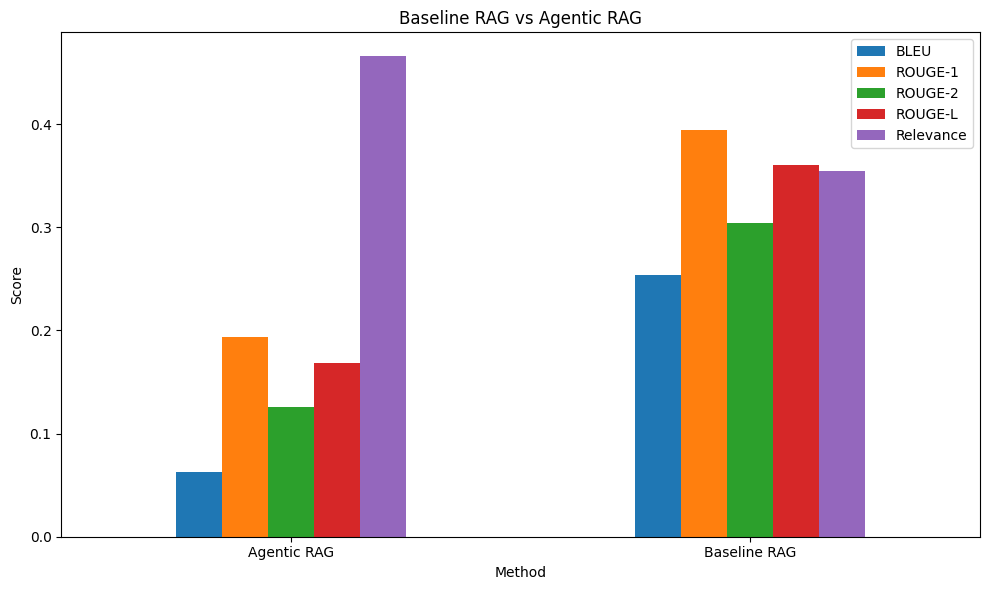

In [43]:
import matplotlib.pyplot as plt

plot_df = summary_df.set_index("method")[metric_columns]

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Baseline RAG vs Agentic RAG")
ax.set_ylabel("Score")
ax.set_xlabel("Method")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "/content/rag_evaluation_comparison.png",
    dpi=200
)

plt.show()


## 33. Save LangGraph workflow diagram

In [44]:
try:
    png_bytes = graph.get_graph().draw_mermaid_png()

    with open("/content/langgraph_workflow.png", "wb") as f:
        f.write(png_bytes)

    print("Saved: /content/langgraph_workflow.png")

except Exception as e:
    print("Diagram export was not available:", e)
    print("\nMermaid representation:")
    print(graph.get_graph().draw_mermaid())


Saved: /content/langgraph_workflow.png


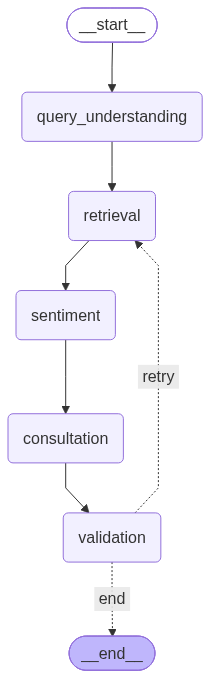

In [45]:
import os
from IPython.display import Image, display

image_path = "/content/langgraph_workflow.png"

if os.path.exists(image_path):
    display(Image(filename=image_path))
else:
    print(f"Warning: {image_path} not found. Attempting to display the live graph instead:")
    try:
        # Dynamically display the graph structure if graph object is available
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print("Could not draw live graph structure:", e)
        try:
            print(graph.get_graph().draw_mermaid())
        except Exception:
            print("Please run cell #33 to compile and save the workflow diagram first.")